# Partie 3 - Flux IoT : pollution urbaine (OpenAQ)

**Bronze** (MinIO `datalake-openaq`) -> **Silver** (`silver_pollution_openaq_clean`) -> **Gold** (une table par question métier).

| Source bronze | Contenu | Produit par |
|---|---|---|
| `inventory/sensors.csv` | capteurs des 11 grandes villes (polluant, unité, coordonnées, ville) | `openaq-inventory.py` |
| `archive/locationid=*/year=*/month=*/*.csv.gz` | historique horaire 2025-2026 | `openaq-download.sh` |
| `stream/<date>/<heure>.jsonl` | flux IoT simulé (un message JSON par mesure) | `openaq-collector.py` |

## **Imports**

In [1]:
import gzip
import io
import json
from concurrent.futures import ThreadPoolExecutor

import boto3
import matplotlib.pyplot as plt
import pandas as pd
from sqlalchemy import create_engine, text

## **Configuration**

In [2]:
# --- CONFIGURATION MINIO ---
MINIO_ENDPOINT = "http://127.0.0.1:9000"
MINIO_ACCESS_KEY = "minioadmin"
MINIO_SECRET_KEY = "minioadmin123"
BUCKET_NAME = "datalake-openaq"

DB_USER = "myuser"
DB_PASSWORD = "mypassword"
DB_HOST = "localhost"
DB_PORT = "5432"
DB_NAME = "mydatabase"

# Polluants et période étudiés
POLLUTANTS = ["pm25", "pm10", "no2", "o3", "co"]
START_DATE = "2025-01-01"

# Masse molaire (g/mol) pour convertir ppm / ppb en µg/m³ (25 °C, 1 atm : volume molaire 24,45 L)
MOLAR_MASS = {"no2": 46.01, "o3": 48.00, "co": 28.01}

# Bornes physiques (µg/m³) : au-delà, la mesure est considérée comme aberrante
MAX_VALUE = {"pm25": 1000, "pm10": 2000, "no2": 2000, "o3": 1000, "co": 100000}

# Seuils journaliers OMS 2021 (µg/m³) : rendent les polluants comparables entre eux
WHO_DAILY = {"pm25": 15, "pm10": 45, "no2": 25, "o3": 100, "co": 4000}

# Connexions
s3_client = boto3.client(
    "s3",
    endpoint_url=MINIO_ENDPOINT,
    aws_access_key_id=MINIO_ACCESS_KEY,
    aws_secret_access_key=MINIO_SECRET_KEY,
)

engine = create_engine(
    f"postgresql+psycopg://{DB_USER}:{DB_PASSWORD}@{DB_HOST}:{DB_PORT}/{DB_NAME}"
)

## **Inventaire des capteurs**

In [3]:
body = s3_client.get_object(Bucket=BUCKET_NAME, Key="inventory/sensors.csv")["Body"].read()
sensors = pd.read_csv(io.BytesIO(body))
print(f"{len(sensors)} capteurs, {sensors['location_id'].nunique()} stations")
sensors.groupby(["city", "pollutant"]).size().unstack(fill_value=0)

268 capteurs, 117 stations


pollutant,co,no2,o3,pm10,pm25
city,,,,,
Bordeaux,0,7,4,6,5
Lille,1,4,3,3,6
Lyon,1,10,6,10,10
Marseille,1,4,2,5,8
Montpellier,0,5,3,3,3
Nantes,1,4,2,4,4
Nice,0,3,4,3,3
Paris,4,28,10,16,20
Rennes,0,3,2,3,3


## **Lister les fichiers MinIO**

In [4]:
def list_keys(prefix, suffix):
    keys = []
    paginator = s3_client.get_paginator("list_objects_v2")
    for page in paginator.paginate(Bucket=BUCKET_NAME, Prefix=prefix):
        keys += [obj["Key"] for obj in page.get("Contents", []) if obj["Key"].endswith(suffix)]
    return keys

archive_keys = list_keys("archive/", ".csv.gz")
stream_keys = list_keys("stream/", ".jsonl")
print(f"{len(archive_keys)} fichiers d'archive, {len(stream_keys)} fichiers du flux IoT")

64773 fichiers d'archive, 1 fichiers du flux IoT


## **Téléchargement & fusion des fichiers**

Les fichiers d'archive sont petits (un par station et par jour) : on les lit en parallèle (32 threads).

In [5]:
def read_archive(key):
    raw = s3_client.get_object(Bucket=BUCKET_NAME, Key=key)["Body"].read()
    return pd.read_csv(io.BytesIO(gzip.decompress(raw)))

with ThreadPoolExecutor(max_workers=32) as pool:
    archive = pd.concat(pool.map(read_archive, archive_keys), ignore_index=True)

# Mêmes noms de colonnes que le flux IoT
archive = archive.rename(columns={
    "sensors_id": "sensor_id", "parameter": "pollutant", "units": "unit",
    "datetime": "timestamp", "lat": "latitude", "lon": "longitude",
})
archive["source"] = "archive"
print(f"Archive : {len(archive):,} lignes")
archive.head()

Archive : 3,105,489 lignes


,location_id,sensor_id,location,timestamp,latitude,longitude,pollutant,unit,value,source
0,2162591,7775307,PARIS 1er Les Halles-2132410,2025-01-01T01:00:00+01:00,48.86212,2.344616,pm10,µg/m³,14.4,archive
1,2162591,7775307,PARIS 1er Les Halles-2132410,2025-01-01T02:00:00+01:00,48.86212,2.344616,pm10,µg/m³,14.9,archive
2,2162591,7775307,PARIS 1er Les Halles-2132410,2025-01-01T19:00:00+01:00,48.86212,2.344616,pm10,µg/m³,14.5,archive
3,2162591,7775307,PARIS 1er Les Halles-2132410,2025-01-02T00:00:00+01:00,48.86212,2.344616,pm10,µg/m³,15.8,archive
4,2162591,7775825,PARIS 1er Les Halles-2132410,2025-01-01T01:00:00+01:00,48.86212,2.344616,pm25,µg/m³,12.1,archive


In [6]:
def read_stream(key):
    raw = s3_client.get_object(Bucket=BUCKET_NAME, Key=key)["Body"].read().decode("utf-8")
    return [json.loads(line) for line in raw.splitlines() if line]

with ThreadPoolExecutor(max_workers=32) as pool:
    stream = pd.DataFrame([m for msgs in pool.map(read_stream, stream_keys) for m in msgs],
                          columns=["sensor_id", "pollutant", "timestamp", "latitude", "longitude",
                                   "value", "unit", "location_id", "city"])
stream["source"] = "stream"
print(f"Flux IoT : {len(stream):,} messages")
stream.head()

Flux IoT : 268 messages


,sensor_id,pollutant,timestamp,latitude,longitude,value,unit,location_id,city,source
0,5603,pm10,2026-10-19T06:00:00Z,45.774820,4.898572,21.8,µg/m³,2680,Lyon,stream
1,7586,co,2026-10-22T06:00:00Z,45.774820,4.898572,359.0,µg/m³,2680,Lyon,stream
2,5587,no2,2026-10-22T06:00:00Z,45.774820,4.898572,47.9,µg/m³,2680,Lyon,stream
3,5588,pm10,2026-10-19T06:00:00Z,48.870274,2.332500,18.5,µg/m³,2681,Paris,stream
4,5620,no2,2026-10-22T06:00:00Z,48.870274,2.332500,20.7,µg/m³,2681,Paris,stream


## **Nettoyage**

1. On garde les 5 polluants étudiés et les capteurs de l'inventaire (l'archive contient aussi NO, SO₂...).
2. Timestamp : conversion en UTC (l'archive est en heure locale avec décalage, le flux en UTC) ; on garde la période étudiée (depuis le 01/01/2025).
3. Unités : conversion de ppm / ppb en µg/m³.
4. Valeurs manquantes, négatives ou au-delà des bornes physiques : supprimées.
5. Doublons (même capteur, même heure, dans l'archive et le flux) : on garde une seule mesure.

In [7]:
COLUMNS = ["sensor_id", "pollutant", "timestamp", "latitude", "longitude", "value", "unit", "source"]
df = pd.concat([archive[COLUMNS], stream[COLUMNS]], ignore_index=True)
n_raw = len(df)
removed = {}

# 1. Polluants et capteurs étudiés
n = len(df)
df = df[df["pollutant"].isin(POLLUTANTS) & df["sensor_id"].isin(sensors["sensor_id"])]
removed["autres polluants (no, so2...) ou capteurs hors inventaire"] = n - len(df)

# 2. Timestamp en UTC (sans fuseau, comme dans la Partie 1), période étudiée uniquement
df["timestamp"] = pd.to_datetime(df["timestamp"], utc=True, errors="coerce", format="ISO8601").dt.tz_localize(None)
n = len(df)
df = df[df["timestamp"] >= START_DATE]
removed[f"timestamp invalide ou antérieur au {START_DATE}"] = n - len(df)

# 3. Conversion des unités en µg/m³
df["value"] = pd.to_numeric(df["value"], errors="coerce")
unit = df["unit"].str.lower()
mw = df["pollutant"].map(MOLAR_MASS)
df.loc[unit == "ppb", "value"] = df["value"] * mw / 24.45
df.loc[unit == "ppm", "value"] = df["value"] * mw / 24.45 * 1000
df["unit"] = "µg/m³"

# 4. Valeurs manquantes et aberrantes
n = len(df)
df = df.dropna(subset=["value", "latitude", "longitude"])
removed["valeur ou coordonnées manquantes"] = n - len(df)
n = len(df)
df = df[(df["value"] >= 0) & (df["value"] <= df["pollutant"].map(MAX_VALUE))]
removed["valeur négative ou au-delà des bornes physiques"] = n - len(df)

# 5. Doublons : le flux IoT (plus récent) l'emporte sur l'archive
n = len(df)
df = (df.sort_values("source", ascending=False)
        .drop_duplicates(subset=["sensor_id", "timestamp"])
        .sort_values(["sensor_id", "timestamp"]))
removed["doublons (même capteur, même heure)"] = n - len(df)

# Ajout de la ville et de la station
df = df.merge(sensors[["sensor_id", "location_id", "location_name", "city"]], on="sensor_id", how="left")

print(f"{n_raw:,} lignes brutes -> {len(df):,} lignes propres")
for reason, count in removed.items():
    print(f"  - {count:>9,} supprimées : {reason}")
print(f"Période : {df['timestamp'].min()} -> {df['timestamp'].max()}")
df.groupby("pollutant")["value"].describe().round(1)

3,105,757 lignes brutes -> 2,555,574 lignes propres
  -   530,364 supprimées : autres polluants (no, so2...) ou capteurs hors inventaire
  -        22 supprimées : timestamp invalide ou antérieur au 2025-01-01
  -         0 supprimées : valeur ou coordonnées manquantes
  -    19,792 supprimées : valeur négative ou au-delà des bornes physiques
  -         5 supprimées : doublons (même capteur, même heure)
Période : 2025-01-01 00:00:00 -> 2026-10-22 08:06:05


,count,mean,std,min,25%,50%,75%,max
pollutant,,,,,,,,
co,42905.0,209.5,127.4,0.0,139.0,183.0,246.0,7293.0
no2,901372.0,19.6,16.6,0.0,7.6,14.4,26.6,435.8
o3,467249.0,59.3,30.7,0.0,38.1,58.7,78.8,788.5
pm10,474596.0,17.1,13.9,0.0,9.2,14.2,21.5,1220.4
pm25,669452.0,9.2,8.9,0.0,4.3,7.0,11.6,747.1


## **Chargement de la table silver**

In [8]:
table_name = "silver_pollution_openaq_clean"
silver = df[["sensor_id", "location_id", "location_name", "city", "pollutant", "timestamp",
             "latitude", "longitude", "value", "unit", "source"]]

silver.head(0).to_sql(table_name, engine, if_exists="replace", index=False)

# COPY : beaucoup plus rapide que to_sql pour plusieurs millions de lignes
buf = io.StringIO()
silver.to_csv(buf, index=False, header=False)
buf.seek(0)
raw_conn = engine.raw_connection()
try:
    with raw_conn.cursor() as cursor:
        with cursor.copy(f"COPY {table_name} FROM STDIN WITH (FORMAT csv)") as copy:
            copy.write(buf.getvalue())
    raw_conn.commit()
finally:
    raw_conn.close()

with engine.begin() as connection:
    connection.execute(text(f"CREATE INDEX ON {table_name} (city, pollutant, timestamp)"))
    total = connection.execute(text(f"SELECT COUNT(*) FROM {table_name}")).scalar()
print(f"{total:,} lignes dans {table_name}")

2,555,574 lignes dans silver_pollution_openaq_clean


## **GOLD Visions**

In [9]:
# Seuils OMS dans une petite table de référence, utilisée par les tables gold
who = pd.DataFrame({"pollutant": list(WHO_DAILY), "who_daily": list(WHO_DAILY.values())})
who.to_sql("ref_pollution_who", engine, if_exists="replace", index=False)

def run_sql(query_sql, table):
    with engine.begin() as connection:
        connection.execute(text(query_sql))
    print(f"Table {table} créée avec succès !")
    return pd.read_sql(f"SELECT * FROM {table}", engine)

### **1. Quelles zones présentent les niveaux de pollution les plus élevés ?**

Pour chaque station : moyenne par polluant, puis **indice = moyenne / seuil journalier OMS** et part des jours au-dessus du seuil.
Les coordonnées permettent une carte dans Metabase.

In [10]:
query_sql = """
DROP TABLE IF EXISTS gold_pollution_zones;

CREATE TABLE gold_pollution_zones AS
WITH journalier AS (
    SELECT city, location_id, location_name, latitude, longitude, pollutant,
           DATE(timestamp) AS jour, AVG(value) AS moyenne_jour
    FROM silver_pollution_openaq_clean
    GROUP BY city, location_id, location_name, latitude, longitude, pollutant, DATE(timestamp)
)
SELECT
    j.city,
    j.location_id,
    j.location_name,
    AVG(j.latitude) AS latitude,
    AVG(j.longitude) AS longitude,
    j.pollutant,
    COUNT(*) AS nb_jours,
    ROUND(CAST(AVG(j.moyenne_jour) AS NUMERIC), 2) AS moyenne,
    ROUND(CAST(AVG(j.moyenne_jour) / w.who_daily AS NUMERIC), 3) AS indice_oms,
    ROUND(CAST(100.0 * AVG(CASE WHEN j.moyenne_jour > w.who_daily THEN 1 ELSE 0 END) AS NUMERIC), 1) AS pct_jours_depassement
FROM journalier j
JOIN ref_pollution_who w ON w.pollutant = j.pollutant
GROUP BY j.city, j.location_id, j.location_name, j.pollutant, w.who_daily
HAVING COUNT(*) >= 30;
"""
zones = run_sql(query_sql, "gold_pollution_zones")

Table gold_pollution_zones créée avec succès !


pollutant,co,no2,o3,pm10,pm25,indice_global
city,,,,,,
Marseille,0.06,1.08,0.58,0.45,0.66,0.73
Paris,0.05,0.90,0.53,0.44,0.60,0.65
Strasbourg,NaN,0.96,0.51,0.43,0.51,0.63
Montpellier,NaN,0.87,0.68,0.40,0.62,0.63
Nice,NaN,0.75,0.69,0.44,0.66,0.62
Toulouse,NaN,0.76,0.69,0.36,0.56,0.56
Lyon,0.05,0.77,0.56,0.39,0.51,0.56
Rennes,NaN,0.56,0.61,0.35,0.66,0.52
Lille,NaN,0.56,0.54,0.38,0.63,0.52


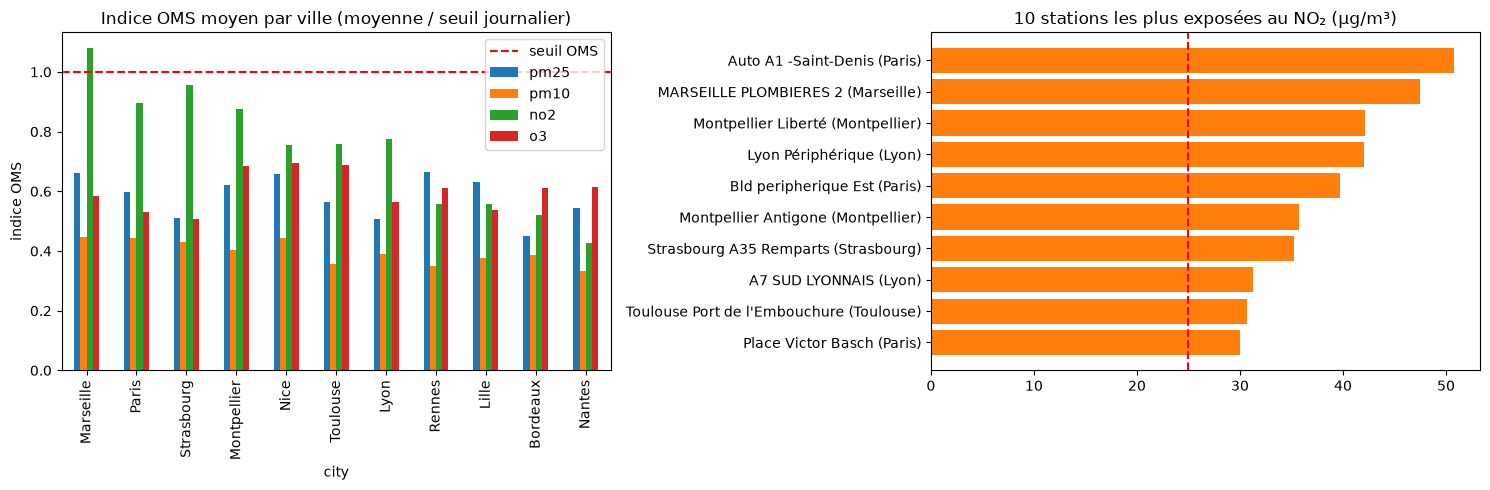

In [11]:
# Classement des villes : indice OMS moyen de leurs stations, par polluant
city_rank = zones.pivot_table(index="city", columns="pollutant", values="indice_oms", aggfunc="mean")
city_rank["indice_global"] = city_rank[["pm25", "pm10", "no2"]].mean(axis=1)
city_rank = city_rank.sort_values("indice_global", ascending=False)
display(city_rank.round(2))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
city_rank[["pm25", "pm10", "no2", "o3"]].plot.bar(ax=axes[0])
axes[0].axhline(1, color="red", ls="--", label="seuil OMS")
axes[0].set_title("Indice OMS moyen par ville (moyenne / seuil journalier)")
axes[0].set_ylabel("indice OMS")
axes[0].legend()

top = zones[zones["pollutant"] == "no2"].nlargest(10, "moyenne")
axes[1].barh(top["location_name"] + " (" + top["city"] + ")", top["moyenne"], color="tab:orange")
axes[1].axvline(WHO_DAILY["no2"], color="red", ls="--")
axes[1].invert_yaxis()
axes[1].set_title("10 stations les plus exposées au NO₂ (µg/m³)")
plt.tight_layout()
plt.show()

#### Interprétation

- **Le NO₂ est le polluant le plus proche du seuil OMS dans presque toutes les villes.** Marseille est la seule ville dont l'indice moyen dépasse 1 (1,08), devant Strasbourg (0,96) et Paris (0,90).
- **En combinant PM2.5, PM10 et NO₂, les villes les plus exposées sont Marseille, Paris, Strasbourg et Montpellier.** Les moins exposées sont Bordeaux et Nantes (indice global ≈ 0,45).
- **À l'échelle des stations, les zones les plus polluées sont les axes routiers** : autoroute A1 à Saint-Denis (≈ 51 µg/m³ de NO₂ en moyenne, deux fois le seuil OMS), Marseille Plombières, Montpellier Liberté, le périphérique lyonnais et le boulevard périphérique parisien. Le NO₂ venant surtout du trafic, la pollution est très localisée : les stations de fond urbain d'une même ville restent bien en dessous.
- Limite : chaque ville n'a pas le même nombre ni le même type de stations (Paris en a 38 dont beaucoup de stations trafic, Rennes 5). Pour comparer finement deux villes, il faut comparer des stations du même type.

### **2. Existe-t-il une variation journalière de la pollution ?**

Moyenne par **heure locale** (Europe/Paris), en distinguant semaine et week-end.

In [12]:
query_sql = """
DROP TABLE IF EXISTS gold_pollution_daily_profile;

CREATE TABLE gold_pollution_daily_profile AS
WITH local AS (
    SELECT city, pollutant, value,
           (timestamp AT TIME ZONE 'UTC') AT TIME ZONE 'Europe/Paris' AS ts_local
    FROM silver_pollution_openaq_clean
)
SELECT
    city,
    pollutant,
    CASE WHEN EXTRACT(ISODOW FROM ts_local) >= 6 THEN 'week-end' ELSE 'semaine' END AS type_jour,
    EXTRACT(HOUR FROM ts_local)::INT AS heure,
    ROUND(CAST(AVG(value) AS NUMERIC), 2) AS moyenne,
    COUNT(*) AS nb_mesures
FROM local
GROUP BY city, pollutant, type_jour, heure
ORDER BY city, pollutant, type_jour, heure;
"""
profile = run_sql(query_sql, "gold_pollution_daily_profile")

Table gold_pollution_daily_profile créée avec succès !


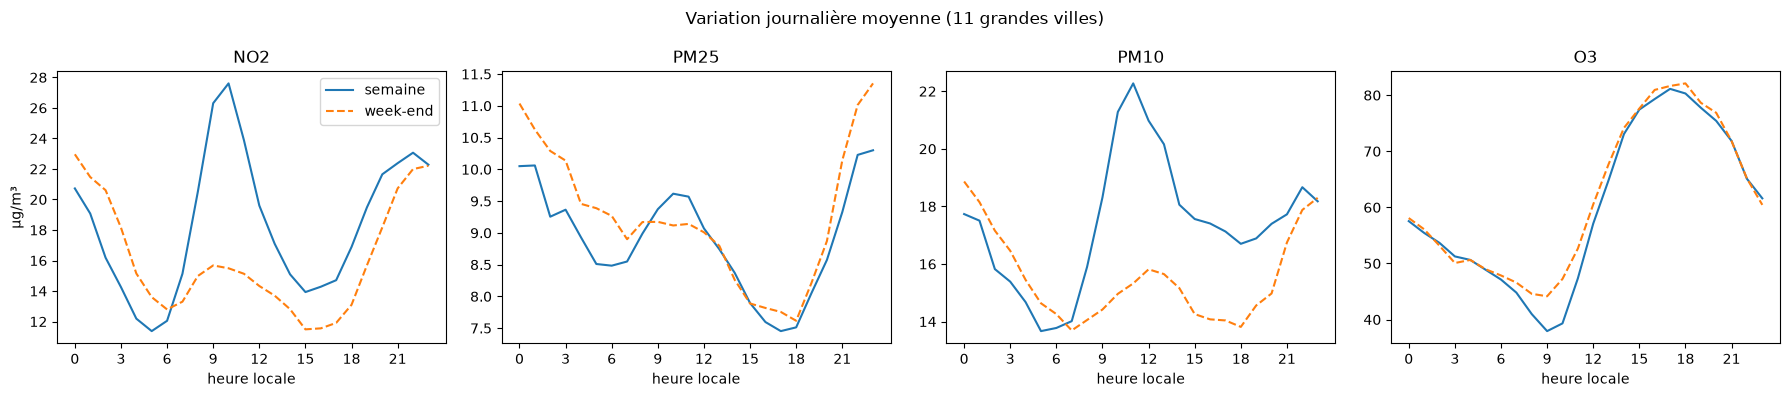

,min,max,heure_pic,amplitude_pct
pollutant,,,,
co,146.302000,259.824000,10,78.0
no2,11.372727,27.607273,10,143.0
o3,37.939091,81.126364,17,114.0
pm10,13.669091,22.271818,11,63.0
pm25,7.453636,10.300000,23,38.0


In [13]:
# Profil horaire France (moyenne des villes)
france = profile.groupby(["pollutant", "type_jour", "heure"])["moyenne"].mean().reset_index()

fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharex=True)
for ax, pol in zip(axes, ["no2", "pm25", "pm10", "o3"]):
    for jour, style in [("semaine", "-"), ("week-end", "--")]:
        d = france[(france["pollutant"] == pol) & (france["type_jour"] == jour)]
        ax.plot(d["heure"], d["moyenne"], style, label=jour)
    ax.set_title(pol.upper())
    ax.set_xlabel("heure locale")
    ax.set_xticks(range(0, 24, 3))
axes[0].set_ylabel("µg/m³")
axes[0].legend()
plt.suptitle("Variation journalière moyenne (11 grandes villes)")
plt.tight_layout()
plt.show()

# Amplitude : écart entre l'heure la plus et la moins polluée
amp = france[france["type_jour"] == "semaine"].groupby("pollutant")["moyenne"].agg(["min", "max", "idxmax"])
amp["heure_pic"] = france.loc[amp["idxmax"], "heure"].values
amp["amplitude_pct"] = (100 * (amp["max"] - amp["min"]) / amp["min"]).round(0)
amp.drop(columns="idxmax")

#### Interprétation

**Oui, la variation journalière est très nette, et elle diffère selon le polluant :**

- **NO₂ (trafic)** : deux pics en semaine, vers 9-10 h et vers 21-22 h, aux heures de pointe. Le pic du matin est presque 2,5 fois plus élevé que le minimum de la nuit (+143 %). **Le week-end, le pic du matin disparaît** presque entièrement : c'est la signature du trafic domicile-travail.
- **PM10** : même pic du matin en semaine (11 h, dû au trafic et à la remise en suspension des poussières), absent le week-end.
- **PM2.5** : faible amplitude (+38 %). Le maximum est **le soir et la nuit (23 h)**, plus marqué le week-end : chauffage au bois en hiver, et couche d'air basse le soir qui empêche les particules de se disperser.
- **O₃** : profil inverse des autres. Il est minimal le matin et maximal vers **17 h**, car l'ozone se forme sous l'effet du soleil à partir des polluants émis le matin. Il est identique en semaine et le week-end.

### **3. Quels polluants sont les plus dominants dans la ville étudiée ?**

Les concentrations brutes ne sont pas comparables (le CO se mesure en milliers de µg/m³).
On compare donc chaque polluant **à son seuil OMS** : un indice de 1 signifie « au niveau du seuil ».

In [14]:
query_sql = """
DROP TABLE IF EXISTS gold_pollution_dominant;

CREATE TABLE gold_pollution_dominant AS
WITH journalier AS (
    SELECT city, pollutant, DATE(timestamp) AS jour, AVG(value) AS moyenne_jour
    FROM silver_pollution_openaq_clean
    GROUP BY city, pollutant, DATE(timestamp)
),
par_polluant AS (
    SELECT
        j.city,
        j.pollutant,
        AVG(j.moyenne_jour) AS moyenne,
        AVG(j.moyenne_jour) / w.who_daily AS indice_oms,
        100.0 * AVG(CASE WHEN j.moyenne_jour > w.who_daily THEN 1 ELSE 0 END) AS pct_jours_depassement
    FROM journalier j
    JOIN ref_pollution_who w ON w.pollutant = j.pollutant
    GROUP BY j.city, j.pollutant, w.who_daily
)
SELECT
    city,
    pollutant,
    ROUND(CAST(moyenne AS NUMERIC), 2) AS moyenne,
    ROUND(CAST(indice_oms AS NUMERIC), 3) AS indice_oms,
    ROUND(CAST(pct_jours_depassement AS NUMERIC), 1) AS pct_jours_depassement,
    RANK() OVER (PARTITION BY city ORDER BY indice_oms DESC) AS rang
FROM par_polluant
ORDER BY city, rang;
"""
dominant = run_sql(query_sql, "gold_pollution_dominant")
dominant[dominant["rang"] == 1][["city", "pollutant", "indice_oms", "pct_jours_depassement"]]

Table gold_pollution_dominant créée avec succès !


,city,pollutant,indice_oms,pct_jours_depassement
0,Bordeaux,o3,0.610,2.2
4,Lille,pm25,0.636,17.4
9,Lyon,no2,0.777,20.6
14,Marseille,no2,0.835,31.0
19,Montpellier,no2,0.857,29.4
23,Nantes,o3,0.594,3.4
28,Nice,no2,0.756,16.8
32,Paris,no2,0.892,34.4
37,Rennes,pm25,0.675,18.3
41,Strasbourg,no2,0.961,40.0


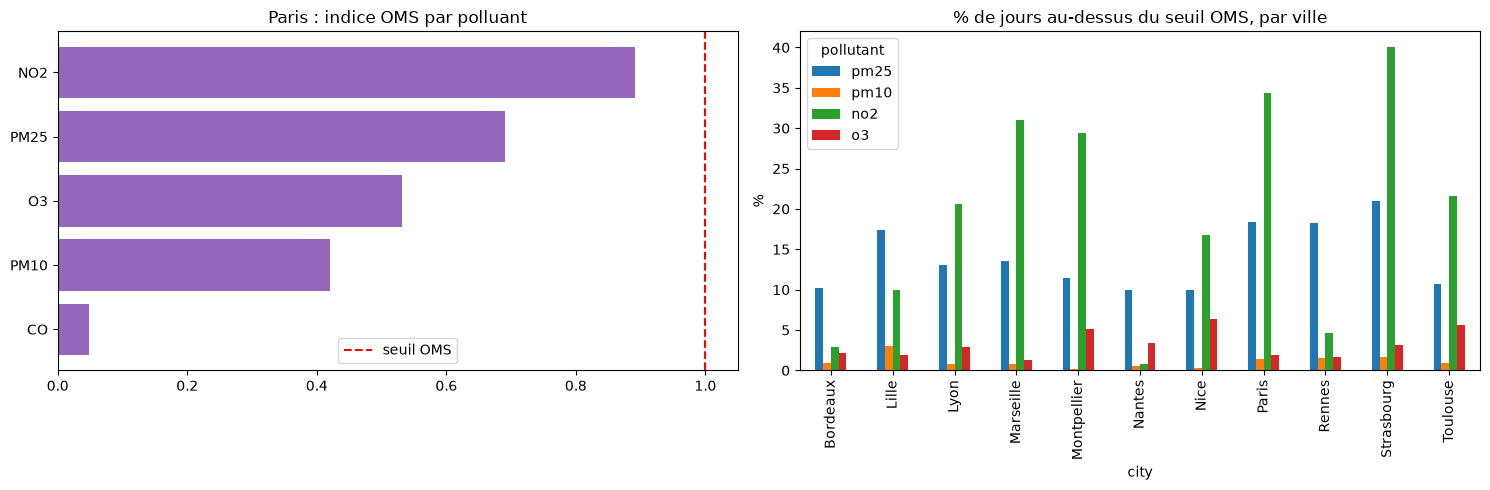

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

d = dominant[dominant["city"] == "Paris"].sort_values("indice_oms")
axes[0].barh(d["pollutant"].str.upper(), d["indice_oms"], color="tab:purple")
axes[0].axvline(1, color="red", ls="--", label="seuil OMS")
axes[0].set_title("Paris : indice OMS par polluant")
axes[0].legend()

pct = dominant.pivot_table(index="city", columns="pollutant", values="pct_jours_depassement")
pct[["pm25", "pm10", "no2", "o3"]].plot.bar(ax=axes[1])
axes[1].set_title("% de jours au-dessus du seuil OMS, par ville")
axes[1].set_ylabel("%")
plt.tight_layout()
plt.show()

#### Interprétation

- Pour comparer des polluants mesurés à des échelles très différentes, on rapporte chaque concentration au seuil journalier de l'OMS.
- **Le NO₂ est le polluant dominant dans 7 villes sur 11** : Paris, Strasbourg, Marseille, Montpellier, Lyon, Toulouse et Nice. À **Paris**, la ville étudiée, il atteint 0,89 fois le seuil OMS en moyenne et **dépasse le seuil un jour sur trois** (34 %). Viennent ensuite les PM2.5 (0,69) et l'O₃ (0,53).
- **Les PM2.5 dominent à Lille et Rennes**, avec 17 à 18 % de jours de dépassement. Ce sont des villes avec moins de trafic de transit, où le chauffage au bois et l'agriculture (épandages au printemps) pèsent davantage.
- **L'O₃ domine à Bordeaux et Nantes**, faute de pollution forte de trafic. Il dépasse rarement le seuil journalier, mais c'est un polluant d'été.
- **Le CO est négligeable** (moins de 0,1 fois le seuil OMS). Il n'est d'ailleurs mesuré que par quelques stations.

### **4. Peut-on identifier des épisodes de pollution anormale ?**

Pour chaque ville et polluant, moyenne journalière comparée à celle **du même mois** (z-score, comme pour la météo en Partie 1).
Un jour est **anormal** si z-score > 2,5 **ou** moyenne > 2 × seuil OMS.
Les jours anormaux consécutifs sont regroupés en **épisodes**.

In [16]:
query_sql = """
DROP TABLE IF EXISTS gold_pollution_anomalies;

CREATE TABLE gold_pollution_anomalies AS
WITH journalier AS (
    SELECT city, pollutant, DATE(timestamp) AS jour, AVG(value) AS moyenne_jour
    FROM silver_pollution_openaq_clean
    GROUP BY city, pollutant, DATE(timestamp)
),
stats AS (
    SELECT city, pollutant, EXTRACT(YEAR FROM jour) AS annee, EXTRACT(MONTH FROM jour) AS mois,
           AVG(moyenne_jour) AS moyenne_mois, STDDEV(moyenne_jour) AS ecart_type_mois
    FROM journalier
    GROUP BY city, pollutant, EXTRACT(YEAR FROM jour), EXTRACT(MONTH FROM jour)
),
scores AS (
    SELECT
        j.city, j.pollutant, j.jour, j.moyenne_jour, s.moyenne_mois, w.who_daily,
        CASE WHEN s.ecart_type_mois > 0 THEN (j.moyenne_jour - s.moyenne_mois) / s.ecart_type_mois ELSE 0 END AS z_score
    FROM journalier j
    JOIN stats s ON s.city = j.city AND s.pollutant = j.pollutant
                AND s.annee = EXTRACT(YEAR FROM j.jour) AND s.mois = EXTRACT(MONTH FROM j.jour)
    JOIN ref_pollution_who w ON w.pollutant = j.pollutant
),
anormaux AS (
    SELECT *,
           -- jours consécutifs -> même numéro d'épisode (technique « gaps and islands »)
           jour - CAST(ROW_NUMBER() OVER (PARTITION BY city, pollutant ORDER BY jour) AS INT) AS groupe
    FROM scores
    WHERE z_score > 2.5 OR moyenne_jour > 2 * who_daily
)
SELECT
    city,
    pollutant,
    jour,
    ROUND(CAST(moyenne_jour AS NUMERIC), 2) AS moyenne_jour,
    ROUND(CAST(moyenne_mois AS NUMERIC), 2) AS moyenne_mois,
    ROUND(CAST(z_score AS NUMERIC), 2) AS z_score,
    ROUND(CAST(moyenne_jour / who_daily AS NUMERIC), 2) AS indice_oms,
    MIN(jour) OVER (PARTITION BY city, pollutant, groupe) AS debut_episode,
    MAX(jour) OVER (PARTITION BY city, pollutant, groupe) AS fin_episode,
    COUNT(*) OVER (PARTITION BY city, pollutant, groupe) AS duree_episode_jours
FROM anormaux
ORDER BY city, pollutant, jour;
"""
anomalies = run_sql(query_sql, "gold_pollution_anomalies")
print(f"{len(anomalies)} jours anormaux (ville x polluant)")

Table gold_pollution_anomalies créée avec succès !
478 jours anormaux (ville x polluant)


In [17]:
# Les épisodes les plus longs / intenses
episodes = (anomalies.groupby(["city", "pollutant", "debut_episode", "fin_episode", "duree_episode_jours"])
            .agg(indice_oms_max=("indice_oms", "max"), z_score_max=("z_score", "max"))
            .reset_index()
            .sort_values(["duree_episode_jours", "indice_oms_max"], ascending=False))
display(episodes.head(15))

# Épisodes touchant plusieurs villes le même jour (épisode national)
multi = (anomalies[anomalies["pollutant"].isin(["pm25", "pm10"])]
         .groupby("jour")["city"].nunique().sort_values(ascending=False))
print("Jours où le plus de villes sont en épisode de particules :")
print(multi.head(10))

,city,pollutant,debut_episode,fin_episode,duree_episode_jours,indice_oms_max,z_score_max
381,Toulouse,pm25,2025-01-15,2025-01-19,5,3.05,2.49
269,Paris,pm25,2026-03-20,2026-03-24,5,2.69,1.69
322,Strasbourg,no2,2025-03-04,2025-03-08,5,2.28,1.73
354,Strasbourg,pm25,2026-01-23,2026-01-26,4,4.10,2.90
317,Rennes,pm25,2026-03-20,2026-03-23,4,3.36,2.92
256,Paris,pm25,2025-02-16,2025-02-19,4,2.84,2.01
304,Rennes,pm25,2025-03-02,2025-03-05,4,2.59,2.12
132,Marseille,pm25,2025-12-30,2026-01-02,4,1.80,3.05
33,Bordeaux,pm25,2026-07-24,2026-07-26,3,6.05,4.25
301,Rennes,pm25,2025-01-13,2025-01-15,3,3.75,3.50


Jours où le plus de villes sont en épisode de particules :
jour
2025-01-15    6
2025-01-19    5
2025-11-14    5
2025-06-10    5
2025-01-20    4
2026-08-14    4
2026-03-07    4
2025-03-03    4
2026-01-02    4
2025-02-18    4
Name: city, dtype: int64


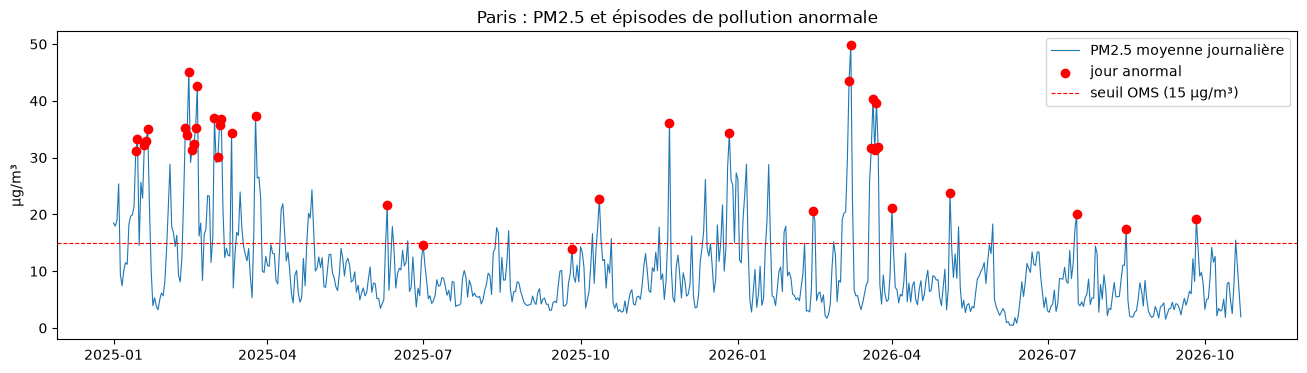

In [18]:
# Série journalière PM2.5 à Paris avec les jours anormaux
query = """
SELECT DATE(timestamp) AS jour, AVG(value) AS pm25
FROM silver_pollution_openaq_clean
WHERE city = 'Paris' AND pollutant = 'pm25'
GROUP BY DATE(timestamp) ORDER BY jour
"""
serie = pd.read_sql(query, engine, parse_dates=["jour"])
anom = anomalies[(anomalies["city"] == "Paris") & (anomalies["pollutant"] == "pm25")]

fig, ax = plt.subplots(figsize=(16, 4))
ax.plot(serie["jour"], serie["pm25"], lw=0.8, label="PM2.5 moyenne journalière")
ax.scatter(pd.to_datetime(anom["jour"]), anom["moyenne_jour"], color="red", zorder=3, label="jour anormal")
ax.axhline(WHO_DAILY["pm25"], color="red", ls="--", lw=0.8, label="seuil OMS (15 µg/m³)")
ax.set_title("Paris : PM2.5 et épisodes de pollution anormale")
ax.set_ylabel("µg/m³")
ax.legend()
plt.show()

#### Interprétation

**Oui. On identifie 480 jours anormaux (ville × polluant), regroupés en épisodes de 1 à 5 jours.**

- **Les particules fines PM2.5 représentent près de la moitié des jours anormaux** (216). Viennent ensuite les PM10 (113) et le NO₂ (97).
- **Les épisodes sont surtout hivernaux et printaniers** : janvier, février et mars concentrent la majorité des épisodes de particules. Cela correspond au chauffage, aux situations anticycloniques froides qui bloquent la dispersion et, en mars, aux épandages agricoles (particules secondaires).
- **Plusieurs épisodes sont nationaux** : le **15 janvier 2025**, 6 villes sont en épisode de particules en même temps, et 5 villes le 19 janvier 2025. On voit aussi des épisodes communs à Paris et Rennes du 20 au 24 mars 2026. Un épisode simultané dans plusieurs villes pointe une cause météorologique (masse d'air stable) plutôt que locale.
- **Les épisodes les plus intenses** : Bordeaux (PM2.5 à 6 fois le seuil OMS fin juillet 2026, un pic estival isolé qui ressemble à des fumées d'incendie) et Strasbourg (4 fois le seuil en janvier 2026).
- La méthode combine deux critères : une hausse inhabituelle pour la saison (z-score) et un niveau sanitaire élevé (2 × seuil OMS). Le premier repère aussi des pics modérés en été, le second les épisodes graves d'hiver.

## **Flux IoT : état de la collecte temps réel**

In [19]:
if len(stream):
    s = stream.copy()
    s["timestamp"] = pd.to_datetime(s["timestamp"], utc=True)
    print(f"{len(stream_keys)} cycles de collecte, {len(s):,} messages, de {s['timestamp'].min()} à {s['timestamp'].max()}")
    display(s.groupby(["city", "pollutant"]).size().unstack(fill_value=0))

1 cycles de collecte, 268 messages, de 2018-01-18 00:00:00+00:00 à 2026-10-22 08:06:05+00:00


pollutant,co,no2,o3,pm10,pm25
city,,,,,
Bordeaux,0,7,4,6,5
Lille,1,4,3,3,6
Lyon,1,10,6,10,10
Marseille,1,4,2,5,8
Montpellier,0,5,3,3,3
Nantes,1,4,2,4,4
Nice,0,3,4,3,3
Paris,4,28,10,16,20
Rennes,0,3,2,3,3
